# Травми й бої

Бої (гекс-бій, обидві сторони веде AI, D61) і травми (D37) за ботами (tech 6.2, «вплив травм»). Метрика спіралі смерті (tech 4.6): тиждень, коли шкала травми вперше дійшла до «важкої» частки максимуму, і скільки після цього культивація стояла.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from simruns import BOTS, label, load, ranks

RUNS, SEED_FROM = 1000, 1  # per bot; data regenerates by itself when Core, Sim.Cli or content changes
data = load(runs=RUNS, seed_from=SEED_FROM)
runs = data.runs
pd.options.display.float_format = "{:.2f}".format
plt.rcParams["figure.figsize"] = (10, 4)


def named(df, axis=0):
    """Replaces content IDs in the index (axis=0) or columns (axis=1) with Ukrainian names."""
    return df.rename(index=label) if axis == 0 else df.rename(columns=label)


def per_run(long, value, by):
    """Mean of value per run for each bot, counting runs where it never happened as zero."""
    total = long.pivot_table(index=by, columns="bot", values=value, aggfunc="sum", fill_value=0)
    return total.div(runs.groupby("bot").size(), axis=1).reindex(columns=list(BOTS), fill_value=0)


## Бої за ботами

Боїв на забіг, частка забігів хоч з одним боєм, частки результатів серед усіх боїв і осяяння з боїв.

In [2]:
g = runs.groupby("bot")
fights = g.fights.sum()
pd.DataFrame({
    "боїв на забіг": g.fights.mean(),
    "забігів із боєм": g.fights.apply(lambda f: (f > 0).mean()),
    "перемога": g.won.sum() / fights,
    "втеча": g.fled.sum() / fights,
    "загибель": g.died.sum() / fights,
    "осяяння з боїв": g.combat_insight.mean(),
}).reindex(list(BOTS))

,боїв на забіг,забігів із боєм,перемога,втеча,загибель,осяяння з боїв
bot,,,,,,
cautious,0.12,0.11,0.97,0.03,0.00,1.59
fighter,63.94,0.98,0.99,0.01,0.00,578.10
random,16.35,0.99,0.91,0.07,0.01,339.50


## Бої за групами ворогів

Усі бої з групою за бот і частки результатів. Решта до 1 — бої, що вичерпали ліміт ходів (D59: відступ).

In [3]:
cg = data.combat_groups.groupby(["group", "bot"])[["won", "fled", "died"]].sum()
total = cg.sum(axis=1)
named(cg.div(total, axis=0).assign(боїв=total))

won  fled  died   боїв
group              bot                             
Дорожні розбійники cautious 0.83  0.17  0.00     18
                   fighter  0.98  0.02  0.00  36277
                   random   0.94  0.06  0.00   9678
Зграя сірих вовків cautious 0.99  0.01  0.00    100
                   fighter  0.99  0.00  0.00  27552
                   random   0.98  0.01  0.01   5770
Річковий змій      fighter  0.78  0.22  0.00     18
                   random   0.44  0.42  0.14     50
Шукачі реліквій    fighter  0.58  0.42  0.00     12
                   random   0.18  0.76  0.06    565

## Пікові травми

Найвище значення шкали кожної травми за забіг (забіги без травми — нуль).

In [4]:
peak = data.injuries.pivot_table(index=["seed", "bot"], columns="injury", values="peak", fill_value=0)
peak = peak.reindex(pd.MultiIndex.from_frame(runs[["seed", "bot"]]), fill_value=0)
named(peak.groupby("bot").describe(percentiles=[0.5, 0.9]).T.unstack(0).swaplevel(axis=1).sort_index(axis=1))

injury injury.body                 injury.internal                
bot       cautious fighter  random        cautious fighter  random
count      1000.00 1000.00 1000.00         1000.00 1000.00 1000.00
mean         10.00    8.66   11.29            5.45   14.88   16.65
std           0.02    2.81    2.51            9.41    7.34    7.10
min          10.00    0.00    0.00            0.00    0.00    0.00
50%          10.00   10.00   10.00            0.00   15.00   15.00
90%          10.00   10.55   15.00           15.00   27.62   28.21
max          10.50   16.67   23.50           38.80   40.80   61.60

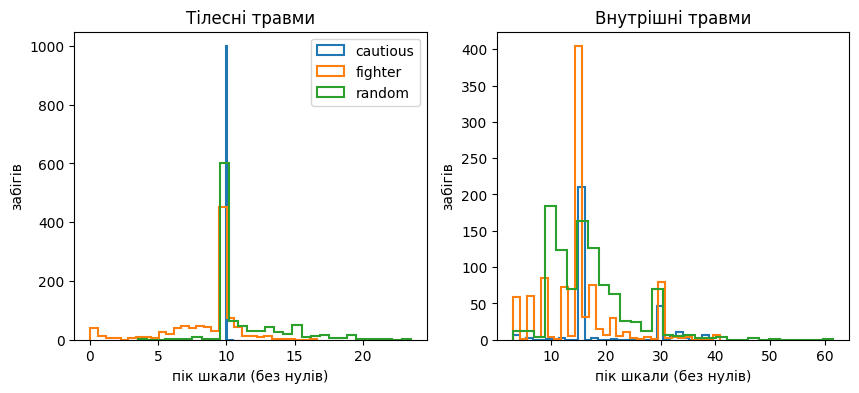

In [5]:
fig, axes = plt.subplots(1, len(peak.columns), figsize=(5 * len(peak.columns), 4))
for ax, injury in zip(axes, peak.columns):
    for bot in BOTS:
        values = peak.xs(bot, level="bot")[injury]
        ax.hist(values[values > 0], bins=30, histtype="step", linewidth=1.5, label=bot)
    ax.set(title=label(injury), xlabel="пік шкали (без нулів)", ylabel="забігів")
axes[0].legend();

## Спіраль смерті

Частка забігів, де травма ставала важкою; серед них — тижні без прогресу культивації після цього і частка тих, хто ще просунувся.

In [6]:
heavy = runs[runs.first_heavy_week.notna()]
hg = heavy.groupby("bot")
pd.DataFrame({
    "забігів із важкою травмою": (heavy.groupby("bot").size() / runs.groupby("bot").size()).fillna(0),
    "тижнів стояння, медіана": hg.weeks_stalled_after_heavy.median(),
    "p90": hg.weeks_stalled_after_heavy.quantile(0.9),
    "просунулись після": hg.progressed_after_heavy.mean(),
}).reindex(list(BOTS))

,забігів із важкою травмою,"тижнів стояння, медіана",p90,просунулись після
bot,,,,
cautious,0.00,NaN,NaN,NaN
fighter,0.00,NaN,NaN,NaN
random,0.00,100.00,132.00,1.00


## Лікування

Тижні на лікування за забіг.

In [7]:
runs.groupby("bot").healing_weeks.describe(percentiles=[0.5, 0.9]).reindex(list(BOTS))

,count,mean,std,min,50%,90%,max
bot,,,,,,,
cautious,1000.00,1.92,4.28,0.00,0.00,4.00,39.00
fighter,1000.00,0.82,2.47,0.00,0.00,4.00,23.00
random,1000.00,35.31,18.05,0.00,35.00,59.00,103.00
